### Step 1: Data Understanding & Preprocessing

**According to your project document, Step 1 requires:**

1. Load and explore the dataset
2. Check missing values
3. Handle missing values
4. Convert categorical variables into numerical format

In [1]:
# 1. Load the dataset
import pandas as pd
import numpy as np

df = pd.read_csv(r"E:\DATA SCIENTIST\ML\repository\project\car_price_prediction.csv")

df.head()

,ID,Price,Levy,Manufacturer,Model,Prod. year,Category,Leather interior,Fuel type,Engine volume,Mileage,Cylinders,Gear box type,Drive wheels,Doors,Wheel,Color,Airbags
0,45654403,13328,1399,LEXUS,RX 450,2010,Jeep,Yes,Hybrid,3.5,186005 km,6.0,Automatic,4x4,04-May,Left wheel,Silver,12
1,44731507,16621,1018,CHEVROLET,Equinox,2011,Jeep,No,Petrol,3,192000 km,6.0,Tiptronic,4x4,04-May,Left wheel,Black,8
2,45774419,8467,-,HONDA,FIT,2006,Hatchback,No,Petrol,1.3,200000 km,4.0,Variator,Front,04-May,Right-hand drive,Black,2
3,45769185,3607,862,FORD,Escape,2011,Jeep,Yes,Hybrid,2.5,168966 km,4.0,Automatic,4x4,04-May,Left wheel,White,0
4,45809263,11726,446,HONDA,FIT,2014,Hatchback,Yes,Petrol,1.3,91901 km,4.0,Automatic,Front,04-May,Left wheel,Silver,4


In [2]:
# 2. Check dataset shape
df.shape

(19237, 18)

In [3]:
# 3. Check column names

print(df.columns.tolist())


['ID', 'Price', 'Levy', 'Manufacturer', 'Model', 'Prod. year', 'Category', 'Leather interior', 'Fuel type', 'Engine volume', 'Mileage', 'Cylinders', 'Gear box type', 'Drive wheels', 'Doors', 'Wheel', 'Color', 'Airbags']


In [4]:
# 4. Identify target column
target = "Price"

In [5]:
# 5. Check data types
df.dtypes

ID                    int64
Price                 int64
Levy                 object
Manufacturer         object
Model                object
Prod. year            int64
Category             object
Leather interior     object
Fuel type            object
Engine volume        object
Mileage              object
Cylinders           float64
Gear box type        object
Drive wheels         object
Doors                object
Wheel                object
Color                object
Airbags               int64
dtype: object

In [6]:
# 6. Check missing values
df.isnull().sum()

ID                  0
Price               0
Levy                0
Manufacturer        0
Model               0
Prod. year          0
Category            0
Leather interior    0
Fuel type           0
Engine volume       0
Mileage             0
Cylinders           0
Gear box type       0
Drive wheels        0
Doors               0
Wheel               0
Color               0
Airbags             0
dtype: int64

In [7]:

missing_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_percentage.sort_values(ascending=False))


ID                  0.0
Price               0.0
Levy                0.0
Manufacturer        0.0
Model               0.0
Prod. year          0.0
Category            0.0
Leather interior    0.0
Fuel type           0.0
Engine volume       0.0
Mileage             0.0
Cylinders           0.0
Gear box type       0.0
Drive wheels        0.0
Doors               0.0
Wheel               0.0
Color               0.0
Airbags             0.0
dtype: float64


In [8]:
# 8. Convert Categorical Variables
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

In [9]:
# Count duplicate rows
print("Total duplicate rows:", df.duplicated().sum())


Total duplicate rows: 313


In [10]:

df[df.duplicated()]


,ID,Price,Levy,Manufacturer,Model,Prod. year,Category,Leather interior,Fuel type,Engine volume,Mileage,Cylinders,Gear box type,Drive wheels,Doors,Wheel,Color,Airbags
425,45815372,7840,-,MERCEDES-BENZ,E 200,1998,Sedan,No,CNG,2,180003 km,4.0,Manual,Rear,04-May,Left wheel,Black,4
1581,45815363,8781,-,TOYOTA,Ist,2002,Hatchback,No,Petrol,1.5,117000 km,4.0,Automatic,4x4,04-May,Right-hand drive,Red,4
1697,45732125,18503,-,TOYOTA,Prius,2010,Sedan,No,Petrol,1.8,162000 km,4.0,Automatic,Front,04-May,Left wheel,Grey,12
1972,45507765,20385,-,MERCEDES-BENZ,CLS 500,2005,Sedan,Yes,Petrol,5,230000 km,8.0,Tiptronic,Rear,04-May,Left wheel,Silver,10
2131,45815363,8781,-,TOYOTA,Ist,2002,Hatchback,No,Petrol,1.5,117000 km,4.0,Automatic,4x4,04-May,Right-hand drive,Red,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18974,45815465,2352,1273,LEXUS,IS 350,2015,Sedan,Yes,Petrol,3.5,80856 km,6.0,Automatic,4x4,04-May,Left wheel,Black,12
19137,45810466,15125,642,CHEVROLET,Orlando,2012,Jeep,Yes,Diesel,2,156834 km,4.0,Automatic,Front,04-May,Left wheel,Golden,4
19200,45725908,36065,640,MERCEDES-BENZ,CLA 250 AMG,2013,Sedan,Yes,Petrol,2.0 Turbo,68000 km,4.0,Tiptronic,Front,04-May,Left wheel,Red,12
19203,45761487,13485,645,TOYOTA,Prius,2011,Sedan,No,Hybrid,1.8,281600 km,6.0,Automatic,Front,04-May,Left wheel,Grey,8


In [11]:

# Display duplicate records
duplicates = df[df.duplicated(keep=False)]

print("Rows involved in duplicates:", len(duplicates))
display(duplicates.head(10))


Rows involved in duplicates: 533


,ID,Price,Levy,Manufacturer,Model,Prod. year,Category,Leather interior,Fuel type,Engine volume,Mileage,Cylinders,Gear box type,Drive wheels,Doors,Wheel,Color,Airbags
1,44731507,16621,1018,CHEVROLET,Equinox,2011,Jeep,No,Petrol,3,192000 km,6.0,Tiptronic,4x4,04-May,Left wheel,Black,8
20,45801686,18826,531,HYUNDAI,Elantra,2012,Sedan,Yes,Petrol,1.6,112645 km,4.0,Automatic,Front,04-May,Left wheel,Silver,4
32,45790136,6899,-,BMW,X5,2000,Jeep,Yes,CNG,4.4,200000 km,8.0,Automatic,4x4,04-May,Left wheel,Silver,6
85,45801684,19121,531,HYUNDAI,Elantra,2012,Sedan,Yes,Petrol,1.6,121362 km,4.0,Automatic,Front,04-May,Left wheel,Black,4
86,45732386,36065,639,HYUNDAI,Santa FE,2014,Jeep,Yes,Diesel,2,69191 km,4.0,Automatic,Front,04-May,Left wheel,White,4
139,44698379,18660,-,HYUNDAI,Sonata,2013,Sedan,Yes,Petrol,2.4,130000 km,4.0,Tiptronic,Front,04-May,Left wheel,Black,6
150,45451626,17876,585,HYUNDAI,Elantra sport limited,2013,Sedan,Yes,Petrol,1.8,117920 km,4.0,Tiptronic,Front,04-May,Left wheel,Grey,12
159,45807577,72130,1079,LEXUS,NX 300,2018,Jeep,Yes,Petrol,2.0 Turbo,18918 km,4.0,Tiptronic,Front,04-May,Left wheel,Black,6
208,45813342,6586,645,LEXUS,CT 200h,2011,Hatchback,Yes,Hybrid,1.8,122302 km,4.0,Automatic,Front,04-May,Left wheel,Black,0
238,45804525,22063,836,HYUNDAI,Tucson,2010,Jeep,Yes,Diesel,2,142264 km,4.0,Automatic,Front,04-May,Left wheel,White,4


In [12]:
print("Levy values:")
print(df["Levy"].head(10).tolist())

print("\nEngine volume values:")
print(df["Engine volume"].head(10).tolist())

print("\nMileage values:")
print(df["Mileage"].head(10).tolist())

print("\nDoors values:")
print(df["Doors"].value_counts())


Levy values:
['1399', '1018', '-', '862', '446', '891', '761', '751', '394', '-']

Engine volume values:
['3.5', '3', '1.3', '2.5', '1.3', '2', '1.8', '2.4', '2.5', '3.5']

Mileage values:
['186005 km', '192000 km', '200000 km', '168966 km', '91901 km', '160931 km', '258909 km', '216118 km', '398069 km', '128500 km']

Doors values:
Doors
04-May    18332
02-Mar      777
>5          128
Name: count, dtype: int64


In [13]:
df.describe()

,ID,Price,Prod. year,Cylinders,Airbags
count,1.923700e+04,1.923700e+04,19237.000000,19237.000000,19237.000000
mean,4.557654e+07,1.855593e+04,2010.912824,4.582991,6.582627
std,9.365914e+05,1.905813e+05,5.668673,1.199933,4.320168
min,2.074688e+07,1.000000e+00,1939.000000,1.000000,0.000000
25%,4.569837e+07,5.331000e+03,2009.000000,4.000000,4.000000
50%,4.577231e+07,1.317200e+04,2012.000000,4.000000,6.000000
75%,4.580204e+07,2.207500e+04,2015.000000,4.000000,12.000000
max,4.581665e+07,2.630750e+07,2020.000000,16.000000,16.000000


In [14]:
# Keep the original dataset safe
df_clean = df.copy()

print("Original dataset shape:", df_clean.shape)


Original dataset shape: (19237, 18)


In [15]:
# 2. Remove duplicate records
df_clean = df_clean.drop_duplicates()

print("Shape after removing duplicates:", df_clean.shape)
print("Remaining duplicate rows:", df_clean.duplicated().sum())


Shape after removing duplicates: (18924, 18)
Remaining duplicate rows: 0


In [16]:
# 3. Convert text-formatted numerical columns

# 1. Clean Levy
df_clean["Levy"] = pd.to_numeric(
    df_clean["Levy"].replace("-", np.nan),
    errors="coerce"
)

# 2. Extract the Turbo information before converting Engine volume
df_clean["Turbo"] = (
    df_clean["Engine volume"]
    .str.contains("Turbo", case=False, na=False)
    .astype(int)
)

# Extract numeric engine volume
df_clean["Engine volume"] = pd.to_numeric(
    df_clean["Engine volume"].str.extract(r"(\d+\.?\d*)")[0],
    errors="coerce"
)

# 3. Remove 'km' and convert Mileage to numeric
df_clean["Mileage"] = pd.to_numeric(
    df_clean["Mileage"].str.replace(" km", "", regex=False),
    errors="coerce"
)

print(df_clean[["Levy", "Engine volume", "Mileage", "Turbo"]].dtypes)
display(df_clean[["Levy", "Engine volume", "Mileage", "Turbo"]].head())


Levy             float64
Engine volume    float64
Mileage            int64
Turbo              int64
dtype: object


,Levy,Engine volume,Mileage,Turbo
0,1399.0,3.5,186005,0
1,1018.0,3.0,192000,0
2,NaN,1.3,200000,0
3,862.0,2.5,168966,0
4,446.0,1.3,91901,0


In [17]:
# Check missing values created during conversion

print("Missing values after conversion:")
print(df_clean.isnull().sum().sort_values(ascending=False).head(10))


Missing values after conversion:
Levy                5709
ID                     0
Price                  0
Manufacturer           0
Model                  0
Prod. year             0
Category               0
Leather interior       0
Fuel type              0
Engine volume          0
dtype: int64


In [18]:

print("Missing values before cleaning:")
print(df_clean.isnull().sum().sort_values(ascending=False).head(10))


Missing values before cleaning:
Levy                5709
ID                     0
Price                  0
Manufacturer           0
Model                  0
Prod. year             0
Category               0
Leather interior       0
Fuel type              0
Engine volume          0
dtype: int64


In [19]:

# Identify numerical and categorical columns
numeric_cols = df_clean.select_dtypes(include=np.number).columns
categorical_cols = df_clean.select_dtypes(exclude=np.number).columns

# Fill numerical missing values with median
for col in numeric_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# Fill categorical missing values with mode
for col in categorical_cols:
    if df_clean[col].isnull().any():
        mode_value = df_clean[col].mode()
        if not mode_value.empty:
            df_clean[col] = df_clean[col].fillna(mode_value[0])

print("Missing values after cleaning:", df_clean.isnull().sum().sum())


Missing values after cleaning: 0


In [20]:

df_clean.info()


<class 'pandas.core.frame.DataFrame'>
Index: 18924 entries, 0 to 19236
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ID                18924 non-null  int64  
 1   Price             18924 non-null  int64  
 2   Levy              18924 non-null  float64
 3   Manufacturer      18924 non-null  object 
 4   Model             18924 non-null  object 
 5   Prod. year        18924 non-null  int64  
 6   Category          18924 non-null  object 
 7   Leather interior  18924 non-null  object 
 8   Fuel type         18924 non-null  object 
 9   Engine volume     18924 non-null  float64
 10  Mileage           18924 non-null  int64  
 11  Cylinders         18924 non-null  float64
 12  Gear box type     18924 non-null  object 
 13  Drive wheels      18924 non-null  object 
 14  Doors             18924 non-null  object 
 15  Wheel             18924 non-null  object 
 16  Color             18924 non-null  object 
 17

In [21]:
# Check the target variable

print(df_clean["Price"].describe())

print("\nMinimum price:", df_clean["Price"].min())
print("Maximum price:", df_clean["Price"].max())
print("Average price:", df_clean["Price"].mean())


count    1.892400e+04
mean     1.858744e+04
std      1.921356e+05
min      1.000000e+00
25%      5.331000e+03
50%      1.317200e+04
75%      2.206300e+04
max      2.630750e+07
Name: Price, dtype: float64

Minimum price: 1
Maximum price: 26307500
Average price: 18587.435267385332


In [22]:
# Final data-cleaning check

print("Final dataset shape:", df_clean.shape)
print("Total duplicate rows:", df_clean.duplicated().sum())
print("Total missing values:", df_clean.isnull().sum().sum())

display(df_clean.head())


Final dataset shape: (18924, 19)
Total duplicate rows: 0
Total missing values: 0


,ID,Price,Levy,Manufacturer,Model,Prod. year,Category,Leather interior,Fuel type,Engine volume,Mileage,Cylinders,Gear box type,Drive wheels,Doors,Wheel,Color,Airbags,Turbo
0,45654403,13328,1399.0,LEXUS,RX 450,2010,Jeep,Yes,Hybrid,3.5,186005,6.0,Automatic,4x4,04-May,Left wheel,Silver,12,0
1,44731507,16621,1018.0,CHEVROLET,Equinox,2011,Jeep,No,Petrol,3.0,192000,6.0,Tiptronic,4x4,04-May,Left wheel,Black,8,0
2,45774419,8467,781.0,HONDA,FIT,2006,Hatchback,No,Petrol,1.3,200000,4.0,Variator,Front,04-May,Right-hand drive,Black,2,0
3,45769185,3607,862.0,FORD,Escape,2011,Jeep,Yes,Hybrid,2.5,168966,4.0,Automatic,4x4,04-May,Left wheel,White,0,0
4,45809263,11726,446.0,HONDA,FIT,2014,Hatchback,Yes,Petrol,1.3,91901,4.0,Automatic,Front,04-May,Left wheel,Silver,4,0


## Step 2: Exploratory Data Analysis (EDA)

In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset only if df_clean does not already exist
df = pd.read_csv("car_price_prediction.csv")

print("Original dataset shape:", df.shape)
print("Columns:", df.columns.tolist())


Original dataset shape: (19237, 18)
Columns: ['ID', 'Price', 'Levy', 'Manufacturer', 'Model', 'Prod. year', 'Category', 'Leather interior', 'Fuel type', 'Engine volume', 'Mileage', 'Cylinders', 'Gear box type', 'Drive wheels', 'Doors', 'Wheel', 'Color', 'Airbags']


In [30]:
# Numerical summary
display(df_clean.describe())

# Categorical summary
display(df_clean.describe(include="object"))

# Target variable summary
print("Average price:", df_clean["Price"].mean())
print("Median price:", df_clean["Price"].median())
print("Minimum price:", df_clean["Price"].min())
print("Maximum price:", df_clean["Price"].max())

,ID,Price,Levy,Prod. year,Engine volume,Mileage,Cylinders,Airbags,Turbo
count,1.892400e+04,1.892400e+04,18924.000000,18924.000000,18924.000000,1.892400e+04,18924.000000,18924.000000,18924.000000
mean,4.557538e+07,1.858744e+04,868.498890,2010.914236,2.306251,1.555373e+06,4.580216,6.568379,0.099979
std,9.375468e+05,1.921356e+05,391.400489,5.665749,0.877591,4.880221e+07,1.200223,4.322323,0.299980
min,2.074688e+07,1.000000e+00,87.000000,1939.000000,0.000000,0.000000e+00,1.000000,0.000000,0.000000
25%,4.569501e+07,5.331000e+03,730.000000,2009.000000,1.800000,7.019575e+04,4.000000,4.000000,0.000000
50%,4.577191e+07,1.317200e+04,781.000000,2012.000000,2.000000,1.264000e+05,4.000000,6.000000,0.000000
75%,4.580174e+07,2.206300e+04,917.000000,2015.000000,2.500000,1.891198e+05,4.000000,12.000000,0.000000
max,4.581665e+07,2.630750e+07,11714.000000,2020.000000,20.000000,2.147484e+09,16.000000,16.000000,1.000000


,Manufacturer,Model,Category,Leather interior,Fuel type,Gear box type,Drive wheels,Doors,Wheel,Color
count,18924,18924,18924,18924,18924,18924,18924,18924,18924,18924
unique,65,1590,11,2,7,4,3,3,2,16
top,HYUNDAI,Prius,Sedan,Yes,Petrol,Automatic,Front,04-May,Left wheel,Black
freq,3729,1069,8600,13731,9944,13282,12695,18032,17471,4944


Average price: 18587.435267385332
Median price: 13172.0
Minimum price: 1
Maximum price: 26307500


**Observation :**
1. Descriptive statistics summarize the numerical features of the dataset.
2. The mean represents the average value, while the median represents the middle value.
3. The minimum and maximum values show the range of car prices.
4. These statistics help us understand the dataset before visualization.

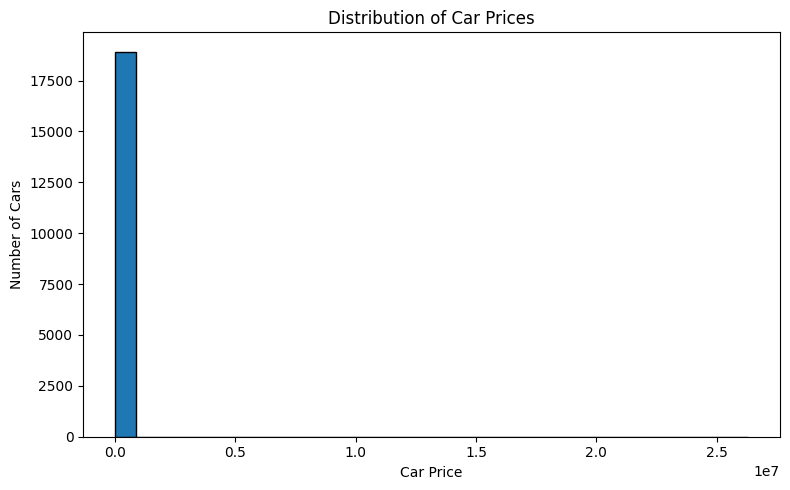

In [31]:
# Histogram of Car Prices
plt.figure(figsize=(8, 5))
plt.hist(df_clean["Price"], bins=30, edgecolor="black")
plt.title("Distribution of Car Prices")
plt.xlabel("Car Price")
plt.ylabel("Number of Cars")
plt.tight_layout()
plt.show()


**Observation :**

1. The histogram shows the distribution of car prices.
2. Taller bars represent price ranges containing more cars.
3. The graph helps identify the most common price ranges.

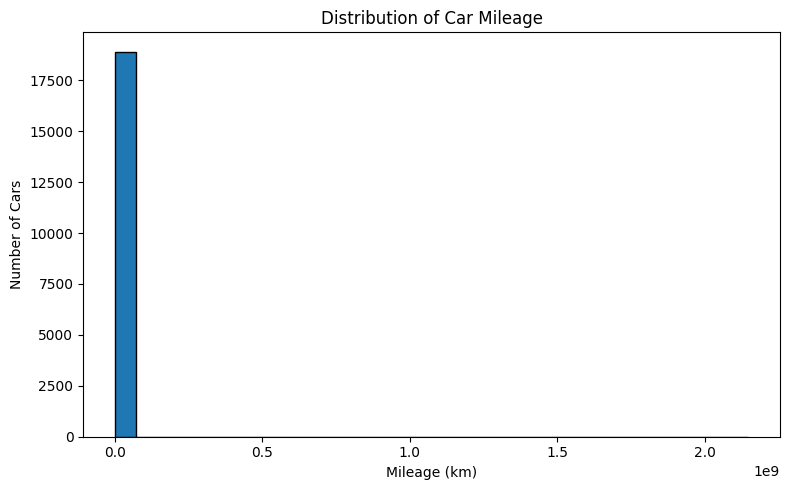

In [33]:
# Histogram of Car Mileage
plt.figure(figsize=(8, 5))
plt.hist(df_clean["Mileage"], bins=30, edgecolor="black")
plt.title("Distribution of Car Mileage")
plt.xlabel("Mileage (km)")
plt.ylabel("Number of Cars")
plt.tight_layout()
plt.show()


**Observation :**

1. The histogram shows how mileage is distributed among cars.
2. Taller bars represent mileage ranges with more cars.
3. The graph helps identify common mileage ranges.

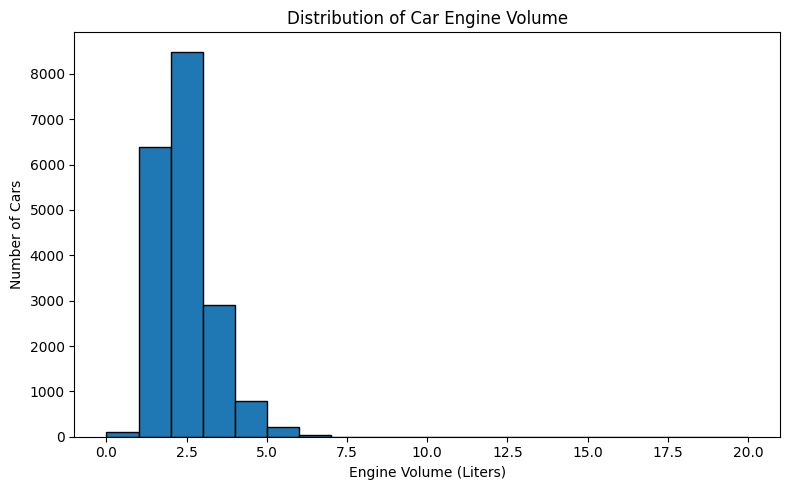

In [34]:
# Histogram of Engine Volume
plt.figure(figsize=(8, 5))
plt.hist(df_clean["Engine volume"], bins=20, edgecolor="black")
plt.title("Distribution of Car Engine Volume")
plt.xlabel("Engine Volume (Liters)")
plt.ylabel("Number of Cars")
plt.tight_layout()
plt.show()


**Observation :**

1. The histogram shows the distribution of engine volumes.
2. The tallest bar represents the most frequent engine-volume range.
3. The graph helps identify the common engine sizes in the dataset.

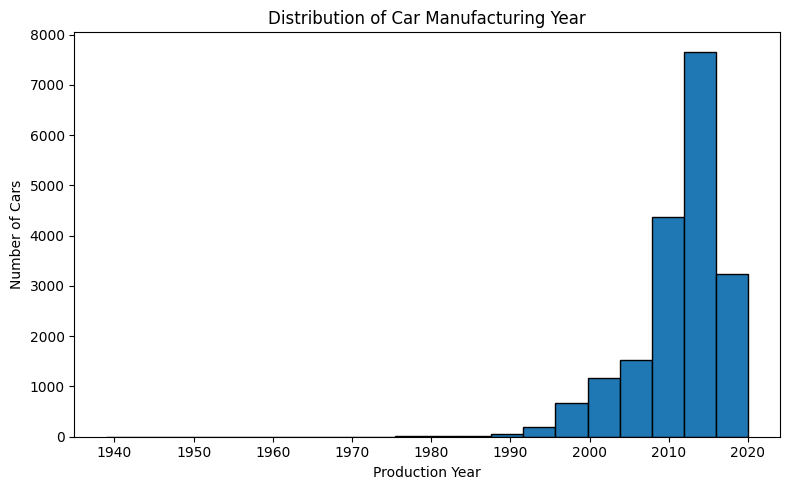

In [35]:
# Histogram of Car Manufacturing Year
plt.figure(figsize=(8, 5))
plt.hist(df_clean["Prod. year"], bins=20, edgecolor="black")
plt.title("Distribution of Car Manufacturing Year")
plt.xlabel("Production Year")
plt.ylabel("Number of Cars")
plt.tight_layout()
plt.show()


**Observation :**

1. The histogram shows the distribution of cars by manufacturing year.
2. Taller bars indicate years or year ranges with more cars.
3. The graph helps compare the number of older and newer cars.

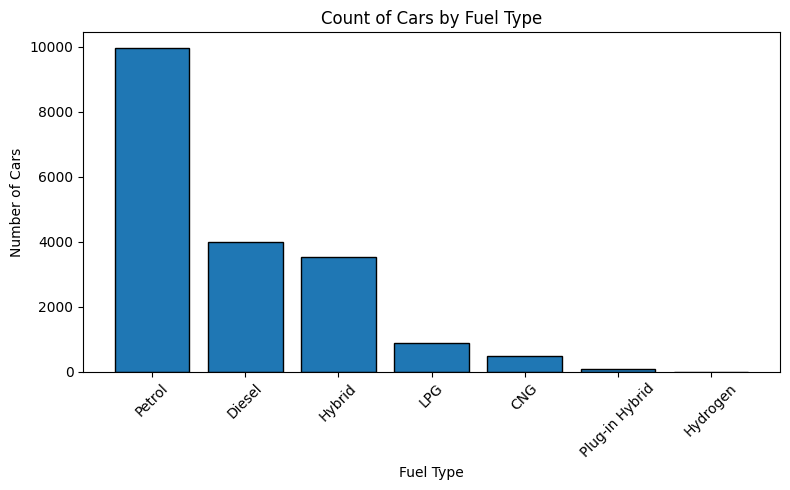

In [36]:
# Count of Cars by Fuel Type
fuel_counts = df_clean["Fuel type"].value_counts()

plt.figure(figsize=(8, 5))
plt.bar(fuel_counts.index, fuel_counts.values, edgecolor="black")
plt.title("Count of Cars by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Number of Cars")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



**Observation  :**

1. The graph shows the number of cars in each fuel category.
2. The tallest bar identifies the most common fuel type.
3. The shortest bar identifies the least common fuel type.
4. Fuel type helps us understand the composition of the dataset.

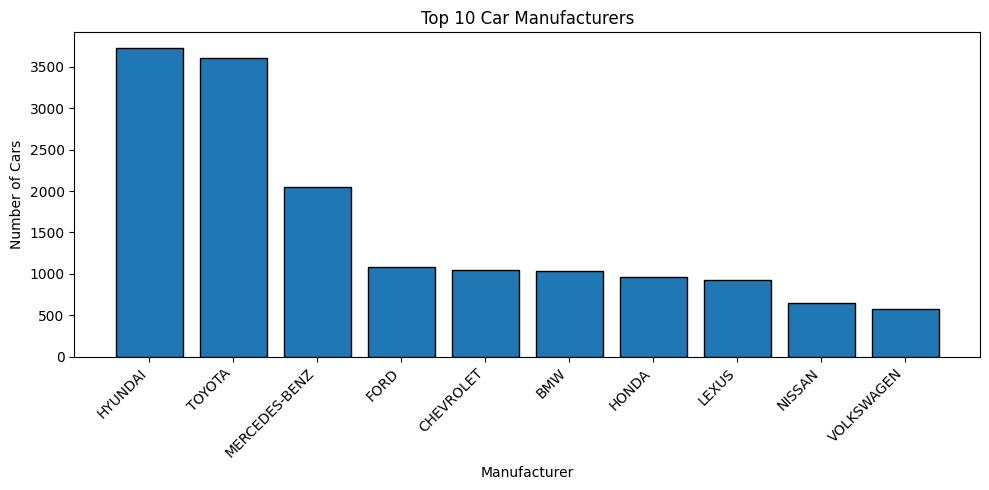

In [37]:
# Top 10 Car Manufacturers
manufacturer_counts = df_clean["Manufacturer"].value_counts().head(10)

plt.figure(figsize=(10, 5))
plt.bar(manufacturer_counts.index, manufacturer_counts.values,
        edgecolor="black")
plt.title("Top 10 Car Manufacturers")
plt.xlabel("Manufacturer")
plt.ylabel("Number of Cars")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


**Observation :**

1. The graph displays the 10 manufacturers with the most records.
2. The tallest bar represents the manufacturer with the most cars in the dataset.
3. The plot shows which manufacturers are most strongly represented.

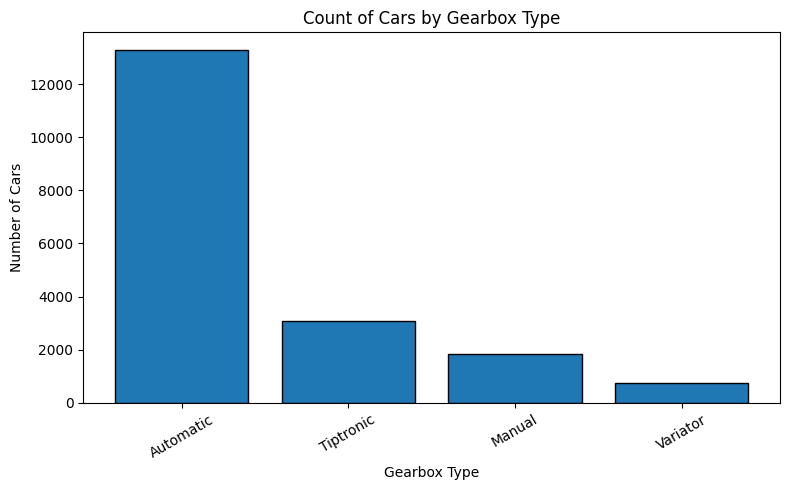

In [38]:
# Count of Cars by Gearbox Type

gearbox_counts = df_clean["Gear box type"].value_counts()

plt.figure(figsize=(8, 5))
plt.bar(gearbox_counts.index, gearbox_counts.values, edgecolor="black")
plt.title("Count of Cars by Gearbox Type")
plt.xlabel("Gearbox Type")
plt.ylabel("Number of Cars")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


**Observation :**

1. The graph compares the number of cars in each gearbox category.
2. The tallest bar indicates the most common gearbox type.
3. The plot helps us understand the distribution of gearbox types.
4. Gearbox type may be useful when analyzing differences in car prices.

#### Scatter Plot

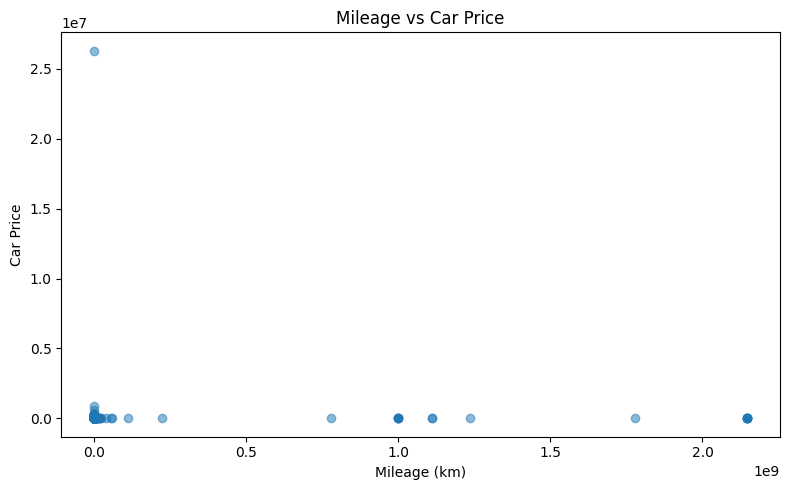

In [40]:
# Mileage vs Price
plt.figure(figsize=(8, 5))
plt.scatter(df_clean["Mileage"], df_clean["Price"], alpha=0.5)
plt.title("Mileage vs Car Price")
plt.xlabel("Mileage (km)")
plt.ylabel("Car Price")
plt.tight_layout()
plt.show()


**Observation :**
1. The scatter plot shows the relationship between mileage and car price.
2. Each point represents one car.
3. A downward pattern would suggest that price tends to decrease as mileage increases.

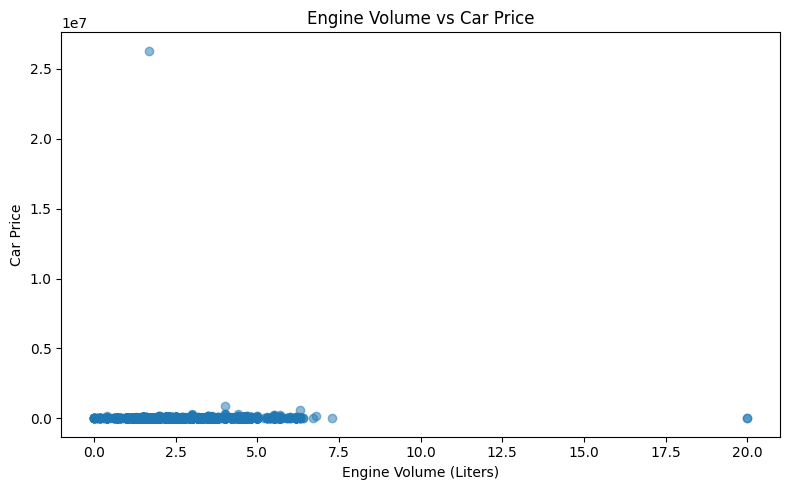

In [41]:
# Engine Volume vs Price

plt.figure(figsize=(8, 5))
plt.scatter(df_clean["Engine volume"], df_clean["Price"], alpha=0.5)
plt.title("Engine Volume vs Car Price")
plt.xlabel("Engine Volume (Liters)")
plt.ylabel("Car Price")
plt.tight_layout()
plt.show()


**Observation :**

1. The scatter plot compares engine volume with car price.
2. Each point represents a car in the dataset.
3. An upward pattern would suggest that cars with larger engines tend to have higher prices.

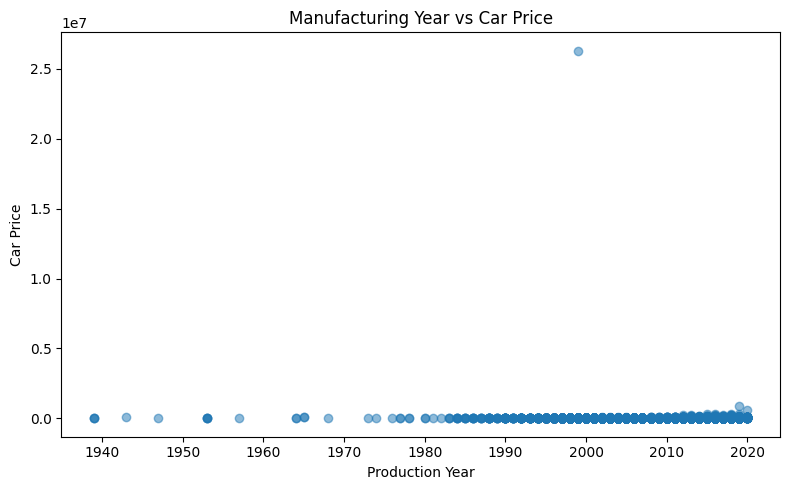

In [42]:
# Manufacturing Year vs Price

plt.figure(figsize=(8, 5))
plt.scatter(df_clean["Prod. year"], df_clean["Price"], alpha=0.5)
plt.title("Manufacturing Year vs Car Price")
plt.xlabel("Production Year")
plt.ylabel("Car Price")
plt.tight_layout()
plt.show()


**Observation :**

1. The graph shows the relationship between production year and car price.
2. Each point represents an individual car.
3. An upward pattern would suggest that newer cars tend to have higher prices.

#### Box Plot

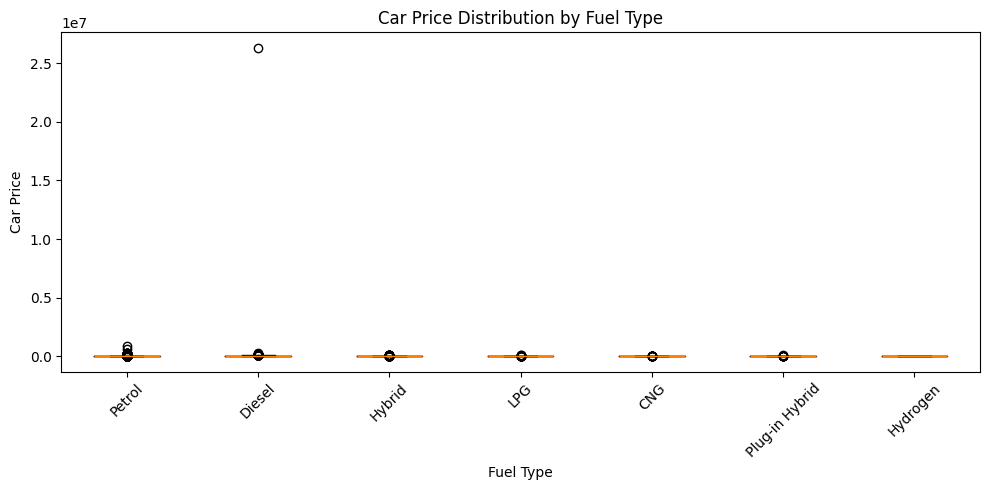

In [43]:
# Price by Fuel Type

fuel_types = df_clean["Fuel type"].value_counts().index
box_data = [
    df_clean.loc[df_clean["Fuel type"] == fuel, "Price"]
    for fuel in fuel_types
]

plt.figure(figsize=(10, 5))
plt.boxplot(box_data, tick_labels=fuel_types)
plt.title("Car Price Distribution by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Car Price")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


**Observation :**
1. The box plot compares car prices across fuel types.
2. The line inside each box represents the median price.
3. The box represents the middle 50% of prices.

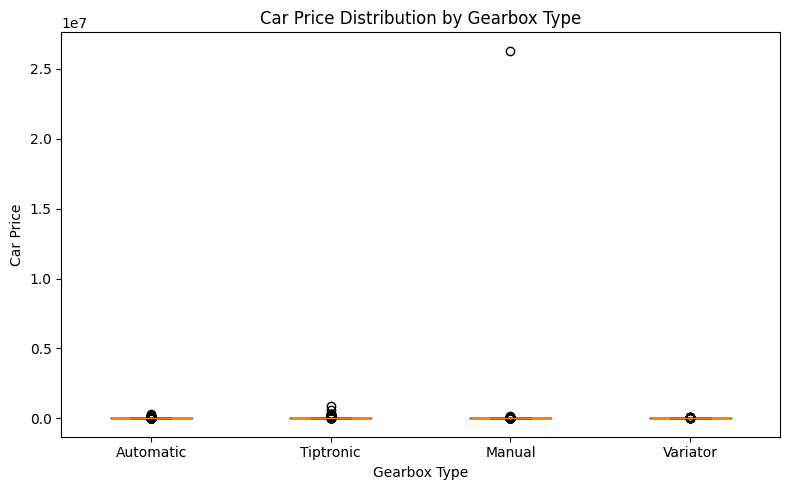

In [44]:
# Price by Gearbox Type
gearbox_types = df_clean["Gear box type"].value_counts().index
box_data = [
    df_clean.loc[df_clean["Gear box type"] == gear, "Price"]
    for gear in gearbox_types
]

plt.figure(figsize=(8, 5))
plt.boxplot(box_data, tick_labels=gearbox_types)
plt.title("Car Price Distribution by Gearbox Type")
plt.xlabel("Gearbox Type")
plt.ylabel("Car Price")
plt.tight_layout()
plt.show()


**Observation :**
1. The box plot compares the price distributions of different gearbox types.
2. The median lines show the typical price for each group.
3. Wider boxes indicate greater variation among the middle 50% of prices.

### Correlation Heatmap

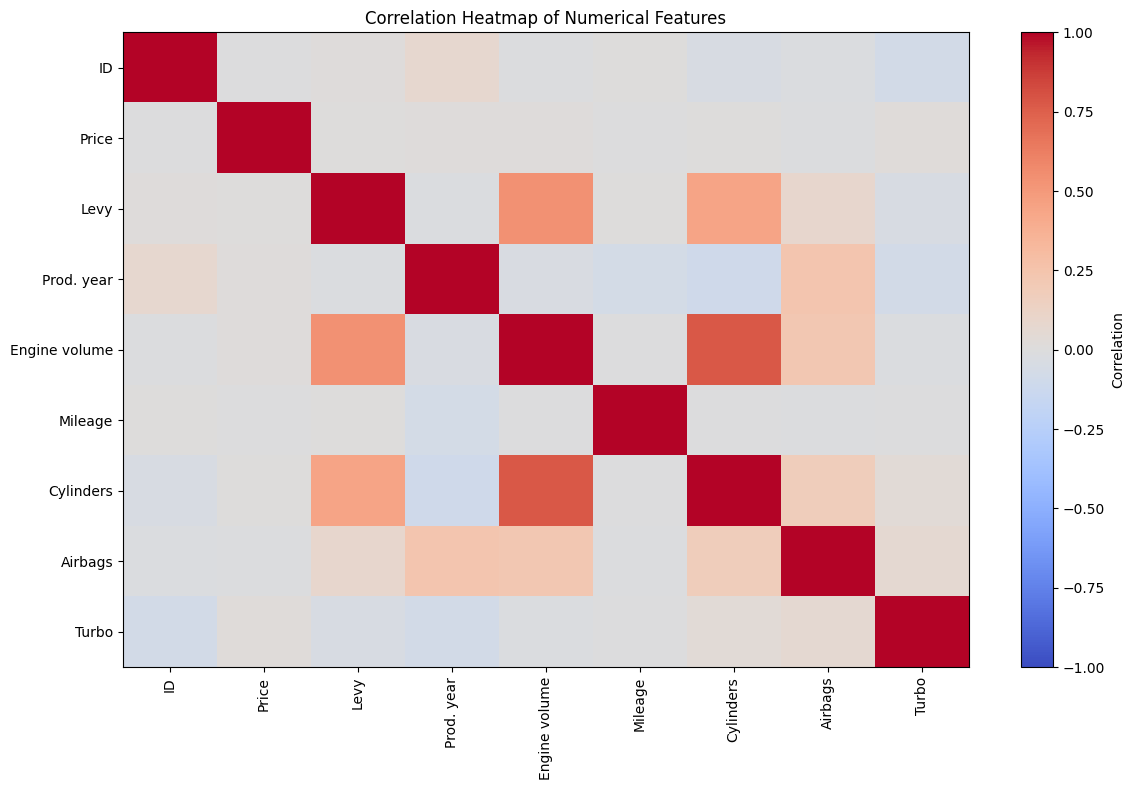

In [45]:

numeric_df = df_clean.select_dtypes(include=np.number)
corr = numeric_df.corr()

plt.figure(figsize=(12, 8))
plt.imshow(corr, cmap="coolwarm", aspect="auto", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()


**Observation :**

1. The heatmap displays correlations between numerical features.
2. Correlation values range from -1 to +1.
3. Positive values indicate that two variables tend to increase together, while negative values indicate an inverse relationship.

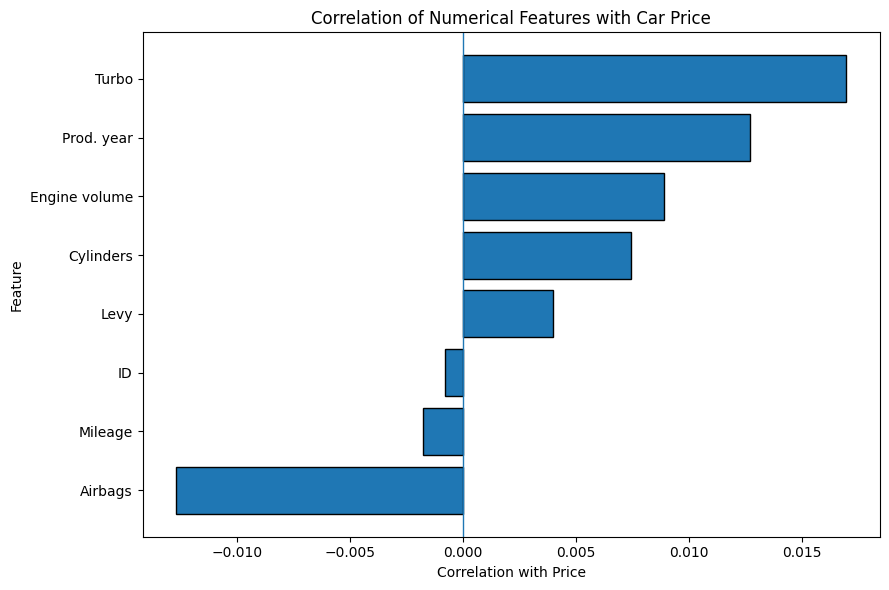

Airbags         -0.012709
Mileage         -0.001763
ID              -0.000797
Levy             0.003982
Cylinders        0.007435
Engine volume    0.008888
Prod. year       0.012689
Turbo            0.016973
Name: Price, dtype: float64


In [46]:
# Correlation of Features with Price
price_corr = corr["Price"].drop("Price").sort_values()

plt.figure(figsize=(9, 6))
plt.barh(price_corr.index, price_corr.values, edgecolor="black")
plt.title("Correlation of Numerical Features with Car Price")
plt.xlabel("Correlation with Price")
plt.ylabel("Feature")
plt.axvline(0, linewidth=1)
plt.tight_layout()
plt.show()

print(price_corr)


**Observation :**
1. The graph ranks numerical features by their correlation with car price.
2. Positive correlations indicate features that tend to increase with price.
3. Negative correlations indicate features that tend to decrease as price increases.

## Step 3: Machine Learning Model Development

In [47]:

# Load the original dataset for model development
df_model = pd.read_csv("car_price_prediction.csv")

# Remove exact duplicate rows
df_model = df_model.drop_duplicates().copy()

# Convert numerical values stored as text
df_model["Levy"] = pd.to_numeric(
    df_model["Levy"].replace("-", np.nan),
    errors="coerce"
)

# Extract Turbo information
df_model["Turbo"] = (
    df_model["Engine volume"]
    .str.contains("Turbo", case=False, na=False)
    .astype(int)
)

# Convert Engine volume to numeric
df_model["Engine volume"] = pd.to_numeric(
    df_model["Engine volume"].str.extract(r"(\d+\.?\d*)")[0],
    errors="coerce"
)

# Convert Mileage to numeric
df_model["Mileage"] = pd.to_numeric(
    df_model["Mileage"].str.replace(" km", "", regex=False),
    errors="coerce"
)

# Input features
X = df_model.drop(columns=["Price", "ID"])

# Target variable
y = df_model["Price"]

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput feature names:")
print(X.columns.tolist())


Input features shape: (18924, 17)
Target shape: (18924,)

Input feature names:
['Levy', 'Manufacturer', 'Model', 'Prod. year', 'Category', 'Leather interior', 'Fuel type', 'Engine volume', 'Mileage', 'Cylinders', 'Gear box type', 'Drive wheels', 'Doors', 'Wheel', 'Color', 'Airbags', 'Turbo']


In [48]:
# Train-Test Split (80% Training, 20% Testing)

from sklearn.model_selection import train_test_split

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)


Training feature shape: (15139, 17)
Testing feature shape: (3785, 17)
Training target shape: (15139,)
Testing target shape: (3785,)


In [49]:
# Preprocessing Numerical and Categorical Features
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Identify numerical and categorical columns
numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical features:", numeric_features)
print("\nCategorical features:", categorical_features)

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data using the fitted preprocessor
X_test_processed = preprocessor.transform(X_test)

print("\nProcessed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)


Numerical features: ['Levy', 'Prod. year', 'Engine volume', 'Mileage', 'Cylinders', 'Airbags', 'Turbo']

Categorical features: ['Manufacturer', 'Model', 'Category', 'Leather interior', 'Fuel type', 'Gear box type', 'Drive wheels', 'Doors', 'Wheel', 'Color']

Processed training shape: (15139, 1511)
Processed testing shape: (3785, 1511)


In [50]:
# Train the Linear Regression Model
from sklearn.linear_model import LinearRegression

# Create the model
lr_model = LinearRegression()

# Train the model
lr_model.fit(X_train_processed, y_train)

print("Linear Regression model trained successfully!")


Linear Regression model trained successfully!


In [51]:

print("Intercept:", lr_model.intercept_)
print("Number of coefficients:", len(lr_model.coef_))


Intercept: 45001.78489774617
Number of coefficients: 1511


In [52]:
# Predict car prices using testing data
y_pred = lr_model.predict(X_test_processed)

print("First 10 Actual Prices:")
print(y_test.iloc[:10].values)

print("\nFirst 10 Predicted Prices:")
print(y_pred[:10])


First 10 Actual Prices:
[11604   470 20162  7527 18817 44003 21326 15681  6899  1333]

First 10 Predicted Prices:
[11268.20274208  8710.99487873 16636.02876697   747.32947642
  9146.90573329 44546.52384812 13495.02168001 28766.30316549
 -3679.25599018  7407.04066216]


In [53]:

comparison = pd.DataFrame({
    "Actual Price": y_test.iloc[:10].values,
    "Predicted Price": y_pred[:10]
})

comparison["Difference"] = (
    comparison["Actual Price"] - comparison["Predicted Price"]
).round(2)

display(comparison.round(2))


,Actual Price,Predicted Price,Difference
0,11604,11268.20,335.80
1,470,8710.99,-8240.99
2,20162,16636.03,3525.97
3,7527,747.33,6779.67
4,18817,9146.91,9670.09
5,44003,44546.52,-543.52
6,21326,13495.02,7830.98
7,15681,28766.30,-13085.30
8,6899,-3679.26,10578.26
9,1333,7407.04,-6074.04


In [54]:
# Model Evaluation

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# Display results
print("Model Evaluation Results")
print("------------------------")
print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 4))


Model Evaluation Results
------------------------
MAE: 14536.46
MSE: 1372026504.66
RMSE: 37040.88
R2 Score: -2.9628


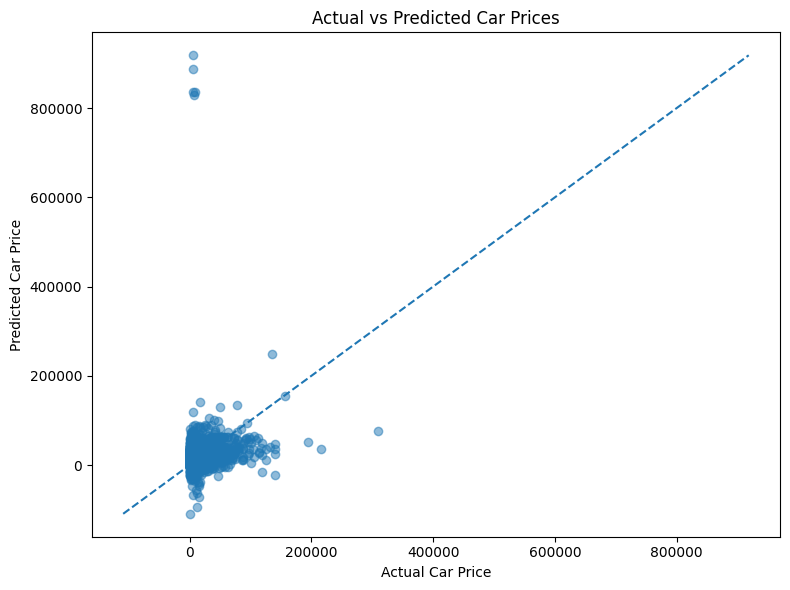

In [55]:
# Visualize Actual vs. Predicted Car Prices

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.5)

# Ideal prediction line
min_price = min(y_test.min(), y_pred.min())
max_price = max(y_test.max(), y_pred.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--"
)

plt.xlabel("Actual Car Price")
plt.ylabel("Predicted Car Price")
plt.title("Actual vs Predicted Car Prices")
plt.tight_layout()
plt.show()


**Observations :**
1. Points close to the diagonal line indicate better predictions.
2. Points far from the line indicate larger prediction errors.

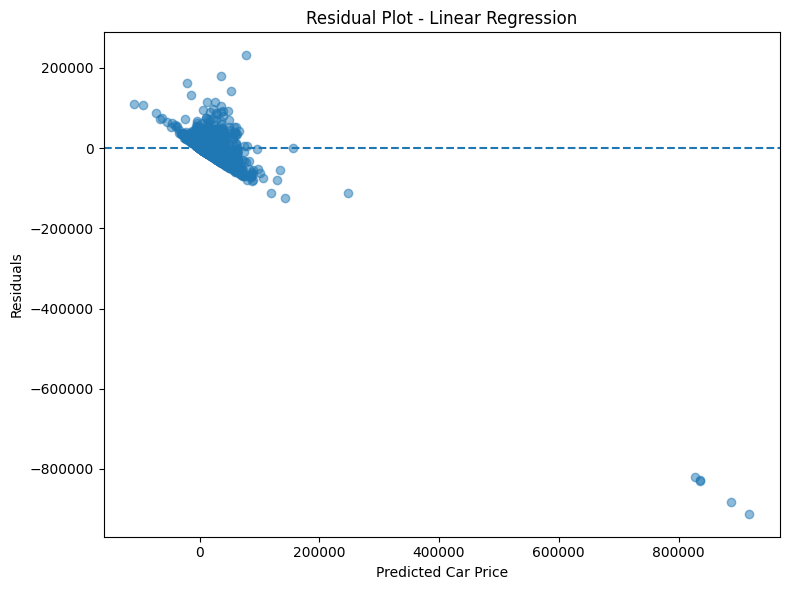

In [56]:

import matplotlib.pyplot as plt

# Calculate residuals
residuals = y_test.to_numpy() - y_pred

# Plot residuals
plt.figure(figsize=(8, 6))
plt.scatter(y_pred, residuals, alpha=0.5)

# Zero reference line
plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted Car Price")
plt.ylabel("Residuals")
plt.title("Residual Plot - Linear Regression")
plt.tight_layout()
plt.show()


In [57]:
# Train a Decision Tree Regressor

from sklearn.tree import DecisionTreeRegressor

# Create the Decision Tree model
dt_model = DecisionTreeRegressor(
    max_depth=10,
    random_state=42
)

# Train the model
dt_model.fit(X_train_processed, y_train)

print("Decision Tree Regressor trained successfully!")


Decision Tree Regressor trained successfully!


In [58]:

# Predict prices on testing data
dt_pred = dt_model.predict(X_test_processed)

# Display actual and predicted prices
dt_comparison = pd.DataFrame({
    "Actual Price": y_test.to_numpy()[:10],
    "Predicted Price": dt_pred[:10]
})

display(dt_comparison.round(2))


,Actual Price,Predicted Price
0,11604,12973.13
1,470,4079.13
2,20162,14552.44
3,7527,6320.67
4,18817,9416.43
5,44003,30815.74
6,21326,14552.44
7,15681,15975.37
8,6899,7645.44
9,1333,14552.44


In [59]:

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

dt_mae = mean_absolute_error(y_test, dt_pred)
dt_mse = mean_squared_error(y_test, dt_pred)
dt_rmse = np.sqrt(dt_mse)
dt_r2 = r2_score(y_test, dt_pred)

print("Decision Tree Evaluation")
print("------------------------")
print("MAE:", round(dt_mae, 2))
print("MSE:", round(dt_mse, 2))
print("RMSE:", round(dt_rmse, 2))
print("R2 Score:", round(dt_r2, 4))


Decision Tree Evaluation
------------------------
MAE: 14545.99
MSE: 182950792790.27
RMSE: 427727.47
R2 Score: -527.411


In [60]:
# Compare both models using evaluation metrics

comparison_df = pd.DataFrame({
    "Metric": ["MAE", "MSE", "RMSE", "R2 Score"],
    "Linear Regression": [
        mae,
        mse,
        rmse,
        r2
    ],
    "Decision Tree": [
        dt_mae,
        dt_mse,
        dt_rmse,
        dt_r2
    ]
})

display(comparison_df.round(4))


,Metric,Linear Regression,Decision Tree
0,MAE,1.453646e+04,1.454599e+04
1,MSE,1.372027e+09,1.829508e+11
2,RMSE,3.704088e+04,4.277275e+05
3,R2 Score,-2.962800e+00,-5.274110e+02


In [61]:

# Compare the models using RMSE and R2 Score

if dt_rmse < rmse and dt_r2 > r2:
    print("Decision Tree performs better on both RMSE and R2 Score.")
elif rmse < dt_rmse and r2 > dt_r2:
    print("Linear Regression performs better on both RMSE and R2 Score.")
else:
    print("The models have mixed results. Compare all metrics before selecting.")


Linear Regression performs better on both RMSE and R2 Score.


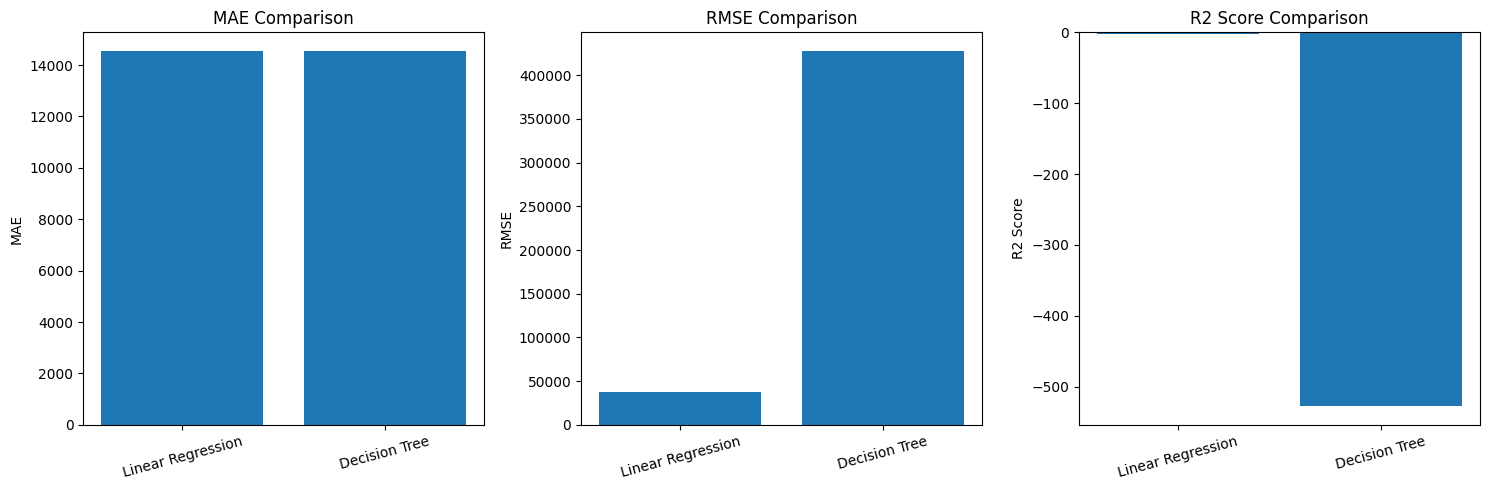

In [62]:

import matplotlib.pyplot as plt
import numpy as np

models = ["Linear Regression", "Decision Tree"]

mae_values = [mae, dt_mae]
rmse_values = [rmse, dt_rmse]
r2_values = [r2, dt_r2]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# MAE comparison
axes[0].bar(models, mae_values)
axes[0].set_title("MAE Comparison")
axes[0].set_ylabel("MAE")
axes[0].tick_params(axis="x", rotation=15)

# RMSE comparison
axes[1].bar(models, rmse_values)
axes[1].set_title("RMSE Comparison")
axes[1].set_ylabel("RMSE")
axes[1].tick_params(axis="x", rotation=15)

# R2 comparison
axes[2].bar(models, r2_values)
axes[2].set_title("R2 Score Comparison")
axes[2].set_ylabel("R2 Score")
axes[2].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()


In [63]:

from sklearn.metrics import mean_squared_error
import numpy as np

# Linear Regression predictions
lr_train_pred = lr_model.predict(X_train_processed)
lr_test_pred = lr_model.predict(X_test_processed)

# Decision Tree predictions
dt_train_pred = dt_model.predict(X_train_processed)
dt_test_pred = dt_model.predict(X_test_processed)

# Calculate RMSE for training and testing data
results = pd.DataFrame({
    "Model": ["Linear Regression", "Decision Tree"],
    "Training RMSE": [
        np.sqrt(mean_squared_error(y_train, lr_train_pred)),
        np.sqrt(mean_squared_error(y_train, dt_train_pred))
    ],
    "Testing RMSE": [
        np.sqrt(mean_squared_error(y_test, lr_test_pred)),
        np.sqrt(mean_squared_error(y_test, dt_test_pred))
    ]
})

display(results.round(2))


,Model,Training RMSE,Testing RMSE
0,Linear Regression,210361.00,37040.88
1,Decision Tree,10477.73,427727.47


In [64]:

from sklearn.ensemble import RandomForestRegressor

# Create the Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train_processed, y_train)

print("Random Forest model trained successfully!")


Random Forest model trained successfully!


In [65]:

# Predict prices on testing data
rf_pred = rf_model.predict(X_test_processed)

# Compare actual and predicted prices
rf_comparison = pd.DataFrame({
    "Actual Price": y_test.iloc[:10].to_numpy(),
    "Predicted Price": rf_pred[:10]
})

display(rf_comparison.round(2))


,Actual Price,Predicted Price
0,11604,18417.58
1,470,2816.12
2,20162,31277.62
3,7527,6590.84
4,18817,10765.42
5,44003,41349.41
6,21326,10966.07
7,15681,15085.20
8,6899,6237.94
9,1333,2980.51


In [66]:

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

rf_mae = mean_absolute_error(y_test, rf_pred)
rf_mse = mean_squared_error(y_test, rf_pred)
rf_rmse = np.sqrt(rf_mse)
rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest Evaluation")
print("------------------------")
print("MAE:", round(rf_mae, 2))
print("MSE:", round(rf_mse, 2))
print("RMSE:", round(rf_rmse, 2))
print("R2 Score:", round(rf_r2, 4))


Random Forest Evaluation
------------------------
MAE: 8750.22
MSE: 47648043045.72
RMSE: 218284.32
R2 Score: -136.6203


In [67]:

# Compare all three trained models

model_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "MAE": [
        mae,
        dt_mae,
        rf_mae
    ],
    "MSE": [
        mse,
        dt_mse,
        rf_mse
    ],
    "RMSE": [
        rmse,
        dt_rmse,
        rf_rmse
    ],
    "R2 Score": [
        r2,
        dt_r2,
        rf_r2
    ]
})

display(model_comparison.round(4))


,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,14536.4649,1.372027e+09,37040.8761,-2.9628
1,Decision Tree,14545.9878,1.829508e+11,427727.4749,-527.4110
2,Random Forest,8750.2181,4.764804e+10,218284.3170,-136.6203


In [68]:

best_model_row = model_comparison.loc[
    model_comparison["RMSE"].idxmin()
]

print("Best Model Based on Test RMSE:")
print(best_model_row["Model"])

print("Test RMSE:", round(best_model_row["RMSE"], 2))
print("Test R2 Score:", round(best_model_row["R2 Score"], 4))


Best Model Based on Test RMSE:
Linear Regression
Test RMSE: 37040.88
Test R2 Score: -2.9628


In [69]:

# Get feature names after preprocessing
feature_names = preprocessor.get_feature_names_out()

# Get feature importance from Random Forest
importance_values = rf_model.feature_importances_

# Create a DataFrame
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

# Show the top 15 features
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(importance_df.head(15).round(4))


,Feature,Importance
1,num__Prod. year,0.5688
5,num__Airbags,0.0598
2,num__Engine volume,0.0507
36,cat__Manufacturer_LAMBORGHINI,0.0367
739,cat__Model_G 65 AMG 63AMG,0.0302
511,cat__Model_Combo,0.0287
1477,cat__Fuel type_Diesel,0.0218
3,num__Mileage,0.0210
1485,cat__Gear box type_Tiptronic,0.0204
0,num__Levy,0.0149


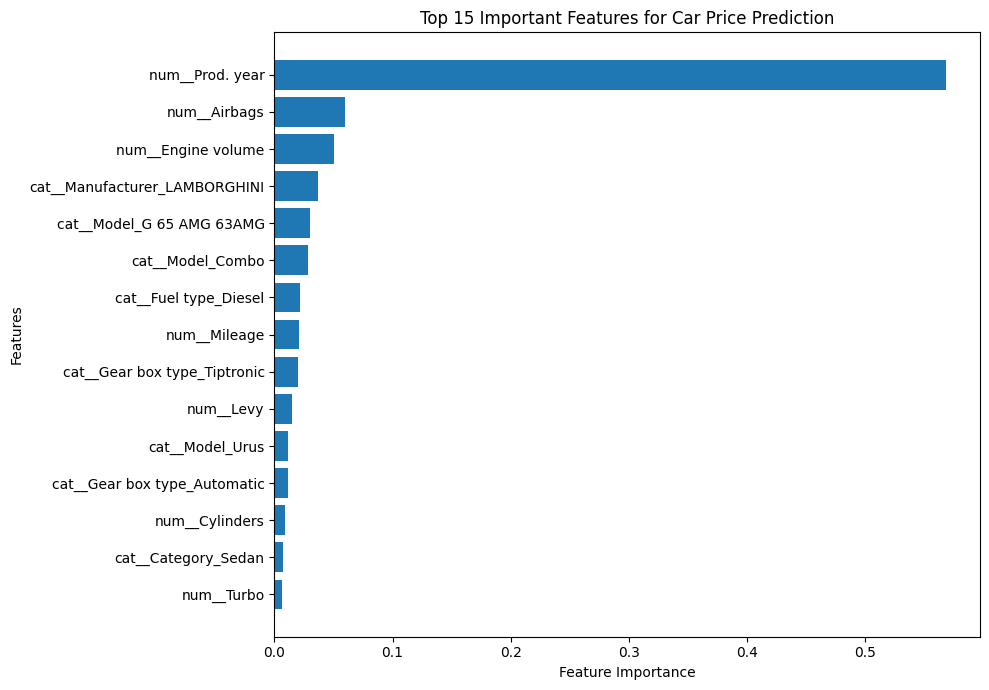

In [70]:

import matplotlib.pyplot as plt

top_features = importance_df.head(15).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Top 15 Important Features for Car Price Prediction")
plt.tight_layout()
plt.show()


In [71]:

import joblib

# Save the trained Random Forest model
joblib.dump(rf_model, "car_price_rf_model.pkl")

# Save the preprocessing pipeline
joblib.dump(preprocessor, "car_price_preprocessor.pkl")

print("Model saved successfully!")
print("Preprocessor saved successfully!")



Model saved successfully!
Preprocessor saved successfully!


In [72]:

# Load saved files
loaded_model = joblib.load("car_price_rf_model.pkl")
loaded_preprocessor = joblib.load("car_price_preprocessor.pkl")

print("Model loaded successfully!")
print("Preprocessor loaded successfully!")


Model loaded successfully!
Preprocessor loaded successfully!


In [73]:

# Select one example from the test dataset
sample_car = X_test.iloc[[0]]

# Transform the sample using the saved preprocessor
sample_processed = loaded_preprocessor.transform(sample_car)

# Predict its price
predicted_price = loaded_model.predict(sample_processed)

print("Predicted Car Price:", round(predicted_price[0], 2))



Predicted Car Price: 18417.58


In [74]:

import pandas as pd
import joblib

# Load saved model and preprocessing pipeline
loaded_model = joblib.load("car_price_rf_model.pkl")
loaded_preprocessor = joblib.load("car_price_preprocessor.pkl")


def predict_car_price(car_details):

    # Convert car details into a DataFrame
    car_df = pd.DataFrame([car_details])

    # Apply preprocessing
    car_processed = loaded_preprocessor.transform(car_df)

    # Predict car price
    predicted_price = loaded_model.predict(car_processed)

    return round(float(predicted_price[0]), 2)


print("Prediction function created successfully!")


Prediction function created successfully!


In [75]:

print("Required car features:")

for column in X.columns:
    print(column)


Required car features:
Levy
Manufacturer
Model
Prod. year
Category
Leather interior
Fuel type
Engine volume
Mileage
Cylinders
Gear box type
Drive wheels
Doors
Wheel
Color
Airbags
Turbo


In [76]:

# Select an existing car from the test dataset
sample_car = X_test.iloc[0].to_dict()

# Predict the price
predicted_price = predict_car_price(sample_car)

print("Predicted Car Price:", predicted_price)
print("Actual Car Price:", y_test.iloc[0])


Predicted Car Price: 18417.58
Actual Car Price: 11604
